In [3]:
import pandas as pd
data=pd.read_csv("Mall_Customers.csv")

In [4]:
X=data[["Age","Annual Income (k$)",	"Spending Score (1-100)"]]

In [5]:
from sklearn.preprocessing import StandardScaler

In [6]:
scaler=StandardScaler()
X_transformes=scaler.fit_transform(X)

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, make_scorer 
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [15]:
best_score=-1
best_k=None
best_model=None
for k in range(2,9):
    model=KMeans(n_clusters=k, init='k-means++', random_state=42)
    labels=model.fit_predict(X_transformes)
    if len(set(labels)) > 1:
        score=silhouette_score(X_transformes, labels)
        print(f"k={k} -> Silhouette Score = {round(score,3)}")
        if score > best_score:
            best_score=score
            best_k = k
            best_model=model

k=2 -> Silhouette Score = 0.335
k=3 -> Silhouette Score = 0.358
k=4 -> Silhouette Score = 0.404
k=5 -> Silhouette Score = 0.408
k=6 -> Silhouette Score = 0.431
k=7 -> Silhouette Score = 0.41
k=8 -> Silhouette Score = 0.367


C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

In [17]:
print("\nMeilleur modele selectionne")
print(f"Nombre optimal de clusters (k): {best_k}")
print("Score de Silhouette optimal: ",round(best_score,3))


Meilleur modele selectionne
Nombre optimal de clusters (k): 6
Score de Silhouette optimal:  0.431


In [18]:
labels=best_model.fit_predict(X_transformes)

C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [19]:
sil=silhouette_score(X_transformes, labels)
db=davies_bouldin_score(X_transformes, labels)
ch=calinski_harabasz_score(X_transformes, labels)
print("\nEvaluation Finale du Clustering")
print("Silhouette Score: ", round(sil,3))
print("Davies Bouldin Score: ", round(db,3))
print("Calinski-Harabasz Score: ", round(ch,3))


Evaluation Finale du Clustering
Silhouette Score:  0.431
Davies Bouldin Score:  0.835
Calinski-Harabasz Score:  134.475


In [20]:
from sklearn.decomposition import PCA

In [21]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_transformes)
print("\nVariance expliquee par PCA1 et PCA2: ", pca.explained_variance_ratio_)


Variance expliquee par PCA1 et PCA2:  [0.44266167 0.33308378]


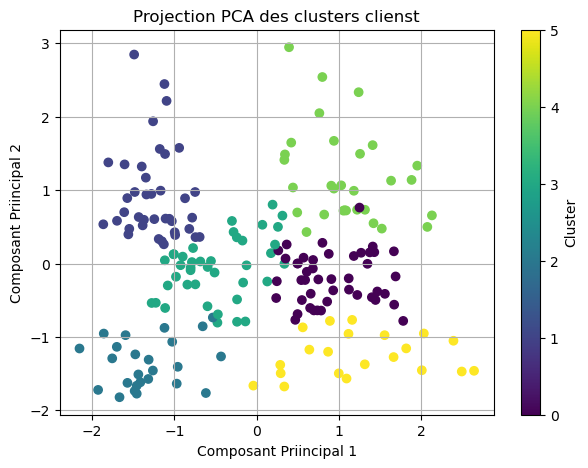

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
plt.scatter(X_pca[:,0],X_pca[:,1], c=labels, cmap="viridis")
plt.xlabel("Composant Priincipal 1")
plt.ylabel("Composant Priincipal 2")
plt.title("Projection PCA des clusters clienst")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

In [23]:
data["Cluster"]=labels

In [24]:
#Interpretqtion des resultats
cluster_means=data.groupby("Cluster")[
    ['Age',	'Annual Income (k$)',	'Spending Score (1-100)']
].mean()

In [25]:
cluster_means

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.333333,54.266667,49.066667
1,32.692308,86.538462,82.128205
2,25.560000,26.480000,76.240000
3,26.125000,59.425000,44.450000
4,44.000000,90.133333,17.933333
5,45.523810,26.285714,19.380952


In [26]:
for cluster_id, ligne in cluster_means.iterrows():
    age=ligne['Age']
    revenu=ligne['Annual Income (k$)']
    depense=ligne['Spending Score (1-100)']
    if revenu > 70 and depense > 60:
        interpretation="Clients premium à fort pouvoir d'achat et forte consommation"
    elif revenu > 70 and depense < 40:
        interpretation="Clients aisés mais peu dépensiers"
    elif revenu < 40 and depense > 60:
        interpretation="Clients impulsifs à faible revenu"
    elif revenu < 40 and depense < 40:
        interpretation="Clients à faible revenu et faible engagement"
    else:
        interpretation="Clients intermediaires"
    print(f"Cluster {cluster_id} -> {interpretation}")

Cluster 0 -> Clients intermediaires
Cluster 1 -> Clients premium à fort pouvoir d'achat et forte consommation
Cluster 2 -> Clients impulsifs à faible revenu
Cluster 3 -> Clients intermediaires
Cluster 4 -> Clients aisés mais peu dépensiers
Cluster 5 -> Clients à faible revenu et faible engagement


In [27]:
import joblib
joblib.dump(best_model, "kmeansModel.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [30]:

import pandas as pd
import numpy as np

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

X_eval = X_transformes

resultats = []

# 1. K-Means
labels_kmeans = KMeans(
    n_clusters=6, init="k-means++", random_state=42, n_init=10
).fit_predict(X_eval)

C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [31]:

import pandas as pd
import numpy as np

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

X_eval = X_transformes

resultats = []

labels_kmeans = KMeans(
    n_clusters=6, init="k-means++", random_state=42, n_init=10
).fit_predict(X_eval)

labels_agg = AgglomerativeClustering(
    n_clusters=6
).fit_predict(X_eval)

labels_dbscan = DBSCAN(
    eps=0.5, min_samples=5
).fit_predict(X_eval)

labels_gmm = GaussianMixture(
    n_components=6, random_state=42, n_init=5
).fit_predict(X_eval)

modeles = {
    "K-Means": labels_kmeans,
    "Agglomerative": labels_agg,
    "DBSCAN": labels_dbscan,
    "GMM": labels_gmm
}

for nom, labels in modeles.items():
    if nom == "DBSCAN":
        masque = labels != -1
    else:
        masque = np.ones(len(labels), dtype=bool)

    labels_eval = labels[masque]
    X_eval_modele = X_eval[masque]
    nb_clusters = len(set(labels_eval))

    if 2 <= nb_clusters < len(labels_eval):
        silhouette = silhouette_score(X_eval_modele, labels_eval)
        davies = davies_bouldin_score(X_eval_modele, labels_eval)
        calinski = calinski_harabasz_score(X_eval_modele, labels_eval)
    else:
        silhouette = np.nan
        davies = np.nan
        calinski = np.nan

    resultats.append({
        "Algorithme": nom,
        "Nombre de clusters": nb_clusters,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": davies,
        "Calinski-Harabasz Score": calinski
    })

tableau_resultats = pd.DataFrame(resultats)
display(tableau_resultats.round(3))


C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

,Algorithme,Nombre de clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,6,0.428,0.825,135.102
1,Agglomerative,6,0.420,0.852,127.986
2,DBSCAN,6,0.482,0.639,117.805
3,GMM,6,0.377,0.871,107.591


In [32]:

import numpy as np

labels = labels_dbscan

groupes, effectifs = np.unique(labels, return_counts=True)

print("Nombre de groupes hors bruit :", len(set(labels) - {-1}))
print("Nombre de clients considérés comme bruit :", np.sum(labels == -1))
print("\nRépartition des clients :")

for groupe, effectif in zip(groupes, effectifs):
    if groupe == -1:
        print(f"Bruit (-1) : {effectif} clients")
    else:
        print(f"Cluster {groupe} : {effectif} clients")


Nombre de groupes hors bruit : 6
Nombre de clients considérés comme bruit : 60

Répartition des clients :
Bruit (-1) : 60 clients
Cluster 0 : 17 clients
Cluster 1 : 5 clients
Cluster 2 : 51 clients
Cluster 3 : 28 clients
Cluster 4 : 32 clients
Cluster 5 : 7 clients


In [34]:
essais_dbscan=[]
for eps in [0.5, 0.7, 0.9, 1.1, 1.3, 1.5]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_transformes)

    masque = labels != -1
    X_gardes = X_transformes[masque]
    labels_gardes = labels[masque]

    nb_clusters = len(set(labels_gardes))
    nb_bruit = np.sum(labels == -1)

    if 2 <= nb_clusters < len(labels_gardes):
        silhouette = silhouette_score(X_gardes, labels_gardes)
    else:
        silhouette = np.nan

    essais_dbscan.append({
        "eps": eps,
        "Nombre de clusters": nb_clusters,
        "Clients bruit": nb_bruit,
        "Silhouette Score": silhouette
    })

display(pd.DataFrame(essais_dbscan).round(3))


,eps,Nombre de clusters,Clients bruit,Silhouette Score
0,0.5,6,60,0.482
1,0.7,1,14,NaN
2,0.9,1,3,NaN
3,1.1,1,0,NaN
4,1.3,1,0,NaN
5,1.5,1,0,NaN


In [35]:

import numpy as np
import pandas as pd

labels_modeles = {
    "K-Means": labels_kmeans,
    "Agglomerative": labels_agg,
    "DBSCAN": labels_dbscan,
    "GMM": labels_gmm
}

for nom, labels in labels_modeles.items():
    groupes, effectifs = np.unique(labels, return_counts=True)

    print(f"\n--- {nom} ---")
    print("Nombre de groupes hors bruit :", len(set(labels) - {-1}))
    print("Nombre de clients classés comme bruit :", np.sum(labels == -1))

    for groupe, effectif in zip(groupes, effectifs):
        print(f"Cluster {groupe} : {effectif} clients")



--- K-Means ---
Nombre de groupes hors bruit : 6
Nombre de clients classés comme bruit : 0
Cluster 0 : 45 clients
Cluster 1 : 39 clients
Cluster 2 : 33 clients
Cluster 3 : 39 clients
Cluster 4 : 23 clients
Cluster 5 : 21 clients

--- Agglomerative ---
Nombre de groupes hors bruit : 6
Nombre de clients classés comme bruit : 0
Cluster 0 : 45 clients
Cluster 1 : 45 clients
Cluster 2 : 39 clients
Cluster 3 : 28 clients
Cluster 4 : 22 clients
Cluster 5 : 21 clients

--- DBSCAN ---
Nombre de groupes hors bruit : 6
Nombre de clients classés comme bruit : 60
Cluster -1 : 60 clients
Cluster 0 : 17 clients
Cluster 1 : 5 clients
Cluster 2 : 51 clients
Cluster 3 : 28 clients
Cluster 4 : 32 clients
Cluster 5 : 7 clients

--- GMM ---
Nombre de groupes hors bruit : 6
Nombre de clients classés comme bruit : 0
Cluster 0 : 13 clients
Cluster 1 : 54 clients
Cluster 2 : 39 clients
Cluster 3 : 23 clients
Cluster 4 : 37 clients
Cluster 5 : 34 clients


In [36]:
import pandas as pd
import numpy as np

resume = []

for nom, labels in labels_modeles.items():
    masque = labels != -1 if nom == "DBSCAN" else np.ones(len(labels), dtype=bool)

    X_eval_modele = X_transformes[masque]
    labels_eval = labels[masque]

    nb_clusters = len(set(labels_eval))

    if 2 <= nb_clusters < len(labels_eval):
        silhouette = silhouette_score(X_eval_modele, labels_eval)
        davies = davies_bouldin_score(X_eval_modele, labels_eval)
        calinski = calinski_harabasz_score(X_eval_modele, labels_eval)
    else:
        silhouette = np.nan
        davies = np.nan
        calinski = np.nan

    resume.append({
        "Algorithme": nom,
        "Clusters hors bruit": nb_clusters,
        "Clients bruit": int(np.sum(labels == -1)),
        "Clients regroupés": int(np.sum(masque)),
        "Silhouette": silhouette,
        "Davies-Bouldin": davies,
        "Calinski-Harabasz": calinski
    })

tableau_final = pd.DataFrame(resume)
display(tableau_final.round(3))

,Algorithme,Clusters hors bruit,Clients bruit,Clients regroupés,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,6,0,200,0.428,0.825,135.102
1,Agglomerative,6,0,200,0.420,0.852,127.986
2,DBSCAN,6,60,140,0.482,0.639,117.805
3,GMM,6,0,200,0.377,0.871,107.591


In [37]:
tableau_final.to_csv(
    "comparaison_algorithmes.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Le tableau comparatif a été enregistré avec succès.")


Le tableau comparatif a été enregistré avec succès.
